# Forecast accuracy and agent check

Two questions about the core of the app:

1. How close is the 91 day cash forecast to what really happened?
2. Does the agent give the same answer every time it sees the same event?

The demo data is a full year, but the app only shows bookings up to "today" (5 May 2025), so the rest of the year
can be used as the truth. `/forecast/backtest` gives the forecast and the real balance per day.

This notebook posts events to the shared demo and calls `/demo/reset` before and after,
so do not run it while someone is presenting the app.

In [1]:
import time
import uuid

import matplotlib.pyplot as plt
import pandas as pd
import requests
from matplotlib.ticker import FuncFormatter

API = "http://api.autonomous-cfo.svc.cluster.local:8080/api/v1"
CLOSURE = {
    "type": "CLOSURE_PLANNED",
    "payload": {"date_from": "2025-06-01", "date_to": "2025-06-30", "variable_costs_stop": True, "note": "summer closure"},
}


def get(path, **params):
    r = requests.get(f"{API}{path}", params=params, timeout=30)
    r.raise_for_status()
    return r.json()


def post(path, body=None):
    r = requests.post(f"{API}{path}", json=body or {}, headers={"Idempotency-Key": str(uuid.uuid4())}, timeout=60)
    r.raise_for_status()
    return r.json()


def eur(cents):
    return int(cents) / 100


def wait_run(run_id, limit=120):
    start = time.time()
    while time.time() - start < limit:
        run = get(f"/runs/{run_id}")
        if run["status"] in ("SUCCEEDED", "FAILED"):
            return run
        time.sleep(1)
    raise TimeoutError(run_id)


def plan_closure():
    version = get("/company")["financial_version"]
    accepted = post("/events", {**CLOSURE, "expected_financial_version": version})
    return wait_run(accepted["run_id"])

plt.rcParams.update({
    "font.size": 10,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
EUR = FuncFormatter(lambda v, _: f"{v:,.0f} €")
pd.set_option("display.max_colwidth", None)

post("/demo/reset")

{'reset': True, 'as_of_date': '2025-05-05', 'financial_version': 1}

## 1. The forecast on its own

The forecast made on 5 May, compared with the balance that was really booked afterwards.

In [2]:
bt = get("/forecast/backtest")
print(bt["note"])
days = pd.DataFrame(bt["days"])
days["date"] = pd.to_datetime(days["date"])
days["actual"] = days["actual"].map(eur)
days["without closure"] = days["forecast"].map(eur)
floor = eur(get("/mandate")["cash_floor"])

Backtest on the sample year: forecast made on 05 May 2025, without Vero's simulated actions, compared with the balance that was actually booked.


## 2. The same forecast, told about the June closure

In the real year the pizzeria closed for June. The weekday model cannot know that from the past.
So the owner's event is posted the same way the app does it (`POST /events`), the agent run is waited for,
and the new forecast is compared with reality again.

In [3]:
run = plan_closure()
print("agent run:", run["status"], "| mode:", run["mode"], "| headline:", run["result"]["headline"]["text"])
fc = get("/forecast")
with_closure = pd.DataFrame(fc["days"])[["date", "closing"]]
with_closure["date"] = pd.to_datetime(with_closure["date"])
days = days.merge(with_closure.rename(columns={"closing": "with closure"}), on="date")
days["with closure"] = days["with closure"].map(eur)


def describe(col):
    below = days[days[col] < floor]
    low = days.loc[days[col].idxmin()]
    row = {
        "first day below the floor": below["date"].min().date() if len(below) else "never",
        "days below the floor": len(below),
        "lowest balance (EUR)": round(low[col], 2),
        "lowest on": low["date"].date(),
        "balance on the last day (EUR)": round(days[col].iloc[-1], 2),
    }
    if col != "actual":
        row["mean daily error vs actual (EUR)"] = round((days[col] - days["actual"]).abs().mean(), 2)
    return row


compare = pd.DataFrame({c: describe(c) for c in ["without closure", "with closure", "actual"]}).fillna("-")
compare

agent run: SUCCEEDED | mode: AGENT | headline: June closure impact and options


,without closure,with closure,actual
first day below the floor,never,2025-06-15,2025-06-15
days below the floor,0,50,48
lowest balance (EUR),-396.3,-22760.82,-22097.6
lowest on,2025-06-01,2025-07-03,2025-07-03
balance on the last day (EUR),2392.2,-20974.5,-11914.55
mean daily error vs actual (EUR),11504.25,2376.94,-


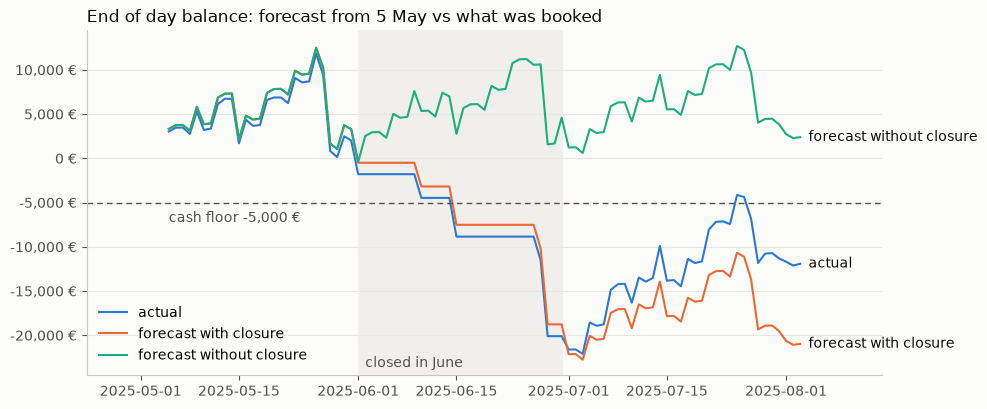

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(pd.Timestamp("2025-06-01"), pd.Timestamp("2025-06-30"), color="#f0efec", zorder=0)
ax.annotate("closed in June", (pd.Timestamp("2025-06-02"), 0), xycoords=("data", "axes fraction"),
            textcoords="offset points", xytext=(0, 6), color=MUTED)
series = [("actual", "actual", BLUE), ("with closure", "forecast with closure", ORANGE),
          ("without closure", "forecast without closure", AQUA)]
for col, label, color in series:
    ax.plot(days["date"], days[col], color=color, linewidth=1.5, label=label, solid_joinstyle="round")
    ax.annotate(label, (days["date"].iloc[-1], days[col].iloc[-1]), textcoords="offset points",
                xytext=(6, 0), va="center", color=INK)
ax.axhline(floor, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate(f"cash floor {floor:,.0f} €", (days["date"].iloc[0], floor), textcoords="offset points",
            xytext=(0, -14), color=MUTED)
ax.yaxis.set_major_formatter(EUR)
ax.margins(x=0.13)
ax.legend(loc="lower left")
ax.set_title("End of day balance: forecast from 5 May vs what was booked", loc="left")
fig.tight_layout()
plt.show()

## 3. Does the agent answer the same way every time?

The closure event is sent five times, each time on a freshly reset demo.
The agent has a budget of 8 tool calls and 60 seconds per run. If the model fails, the app falls back to rules
(`mode = FALLBACK`), so that rate is counted too.

In [5]:
def recommendation_text(rec):
    subject = rec.get("subject") or {}
    if subject.get("ref"):
        return f'{rec["kind"]} {subject["ref"]} to {subject.get("to_date")} ({rec["lane"]})'
    if subject.get("amount"):
        return f'{rec["kind"]} {eur(subject["amount"]):,.0f} EUR ({rec["lane"]})'
    return f'{rec["kind"]} ({rec["lane"]})'


rows = []
for i in range(5):
    post("/demo/reset")
    start = time.perf_counter()
    run = plan_closure()
    seconds = time.perf_counter() - start
    result = run.get("result") or {}
    recs = [get(f"/recommendations/{rid}") for rid in result.get("recommendation_ids", [])]
    kinds = [step["kind"] for step in run.get("trace", [])]
    rows.append({
        "run": i + 1,
        "status": run["status"],
        "mode": run["mode"],
        "seconds": round(seconds, 1),
        "tool calls": kinds.count("TOOL_CALL"),
        "recommendations": "; ".join(sorted(recommendation_text(r) for r in recs)),
        "headline by": (result.get("headline") or {}).get("source"),
    })
runs = pd.DataFrame(rows)
runs

,run,status,mode,seconds,tool calls,recommendations,headline by
0,1,SUCCEEDED,AGENT,23.3,4,"CREDIT_LINE 20,000 EUR (NEEDS_APPROVAL); RESCHEDULE_PAYMENT CHF-06 to 2025-07-30 (NEEDS_APPROVAL)",MODEL
1,2,SUCCEEDED,AGENT,24.3,4,"CREDIT_LINE 20,000 EUR (NEEDS_APPROVAL); RESCHEDULE_PAYMENT CHF-06 to 2025-07-30 (NEEDS_APPROVAL)",TEMPLATE
2,3,SUCCEEDED,AGENT,23.3,4,"CREDIT_LINE 20,000 EUR (NEEDS_APPROVAL); RESCHEDULE_PAYMENT CHF-06 to 2025-07-30 (NEEDS_APPROVAL)",MODEL
3,4,SUCCEEDED,AGENT,24.3,4,"CREDIT_LINE 20,000 EUR (NEEDS_APPROVAL); RESCHEDULE_PAYMENT CHF-06 to 2025-07-30 (NEEDS_APPROVAL)",MODEL
4,5,SUCCEEDED,AGENT,23.3,4,"CREDIT_LINE 20,000 EUR (NEEDS_APPROVAL); RESCHEDULE_PAYMENT CHF-06 to 2025-07-30 (NEEDS_APPROVAL)",MODEL


In [6]:
pd.Series({
    "runs": len(runs),
    "finished in AGENT mode": f'{(runs["mode"] == "AGENT").sum()} / {len(runs)}',
    "median time (s)": runs["seconds"].median(),
    "slowest run (s), budget 60": runs["seconds"].max(),
    "most tool calls, budget 8": runs["tool calls"].max(),
    "same recommendations every run": runs["recommendations"].nunique() == 1,
    "headline written by the model": f'{(runs["headline by"] == "MODEL").sum()} / {len(runs)}',
}, name="result")

runs                                  5
finished in AGENT mode            5 / 5
median time (s)                    23.3
slowest run (s), budget 60         24.3
most tool calls, budget 8             4
same recommendations every run     True
headline written by the model     4 / 5
Name: result, dtype: object

Clean up, so the demo starts from 5 May again.

In [7]:
reset = post("/demo/reset")
reset, len(get("/runs"))

({'reset': True, 'as_of_date': '2025-05-05', 'financial_version': 1}, 0)

## What we take from it

- Without the closure the weekday forecast follows May almost exactly, but it cannot see June coming:
  it never goes below the floor, and the mean daily error over the 91 days is 11 504 €.
- With the owner's closure event the same engine finds the real first day below the floor (15 June)
  and the lowest day (3 July: -22 761 € forecast, -22 098 € real, about 3 % apart). The mean daily error drops to 2 377 €.
- After the reopening the forecast stays more pessimistic than reality, because it assumes the spring weekday
  averages with no seasonal uplift (one of the forecast's stated assumptions). For a cash warning that is the safer side.
- The agent was stable in all 5 runs: AGENT mode every time, about 22 - 24 s (budget 60 s), 4 tool calls (budget 8)
  and the same two recommendations each time: move the CHF-06 partner transfer to 30 July and a 20 000 € credit line.
  Both wait for the owner's approval, because the mandate says "always ask before acting".
- The short headline is written by the model in most runs. When the model needs longer than the explain timeout,
  the app shows a template headline instead, so the owner never waits for it. The table above shows how often that happened.